# Task 3 — YOLOv8 Classification (nano vs small)

**Goal:** train the Ultralytics YOLOv8 classification models selected in the Task 1 memo on **exactly the same 70/15/15 split** as Task 2, measure quality and cost, and compare them with the MobileNetV3-Small baseline.

| | |
|---|---|
| Variants | **YOLOv8n-cls** (nano, 1.4 M params) and **YOLOv8s-cls** (small, 5.1 M params), both ImageNet-pretrained |
| Regime | full fine-tuning: all layers trained, which is the Ultralytics default for classification |
| Dataset | `yolo_dataset/{train,val,test}/{good,bad}` built from `common/split_70_15_15.jsonl` by [`build_yolo_dataset.py`](build_yolo_dataset.py) |
| Seed | **24500003** (student ID), `deterministic=True` |
| Hardware | i7-10750H, CPU |
| Positive class | **bad** (all metrics are computed with the shared `quality_common` code, same as Task 2) |

The test folder is used **only** in the evaluation section. Ultralytics selects `best.pt` by validation top-1 accuracy, so validation only.

In [1]:
import os, json, sys, time, shutil
from pathlib import Path
os.environ["YOLO_VERBOSE"] = "False"          # keep the notebook readable (no progress bars)

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from ultralytics import YOLO
import ultralytics

sys.path.insert(0, str(Path.cwd().parent / "common"))
import quality_common as qc

OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
RUNS = Path("runs").resolve()

# ---- training hyperparameters (identical for both variants) ----
HP = {
    "seed": qc.SEED,
    "imgsz": 224,
    "epochs": 25,
    "patience": 8,                 # Ultralytics early stopping on validation top-1
    "batch": 32,
    "optimizer": "AdamW",
    "lr0": 1e-3,
    "lrf": 0.01,                   # linear decay to lr0 * lrf
    "warmup_epochs": 3,
    "weight_decay": 5e-4,
    "deterministic": True,
    "device": "cpu",
    "workers": 0,
    # augmentation: no flips (mirrored text is unrealistic), no random erasing (it would
    # look like the "occlusion" defect on GOOD images), no RandAugment (contrast/brightness
    # changes look like the "exposure" defect), mild colour jitter, no random crop
    "fliplr": 0.0, "flipud": 0.0, "erasing": 0.0, "auto_augment": None,
    "hsv_h": 0.0, "hsv_s": 0.2, "hsv_v": 0.15, "scale": 0.0,
}
VARIANTS = {"yolov8n_cls": "yolov8n-cls.pt", "yolov8s_cls": "yolov8s-cls.pt"}
print("ultralytics", ultralytics.__version__, "| torch", torch.__version__)
print(json.dumps(HP, indent=2))

ultralytics 8.4.189 | torch 2.14.1+cpu
{
  "seed": 24500003,
  "imgsz": 224,
  "epochs": 25,
  "patience": 8,
  "batch": 32,
  "optimizer": "AdamW",
  "lr0": 0.001,
  "lrf": 0.01,
  "warmup_epochs": 3,
  "weight_decay": 0.0005,
  "deterministic": true,
  "device": "cpu",
  "workers": 0,
  "fliplr": 0.0,
  "flipud": 0.0,
  "erasing": 0.0,
  "auto_augment": null,
  "hsv_h": 0.0,
  "hsv_s": 0.2,
  "hsv_v": 0.15,
  "scale": 0.0
}


## 1. YOLO classification dataset (same split as Task 2)

Ultralytics expects one folder per split and one sub-folder per class. The script reads the shared split file:
- **train** images get a random 0/90/180/270° rotation (both classes, fixed seed). This is the same orientation augmentation as in Task 2, which removes the "rotated = good" shortcut.
- **val** and **test** images are copied unchanged.

In [2]:
from build_yolo_dataset import build
DATA = build()
manifest = pd.read_csv(DATA / "manifest.csv")
print(manifest.groupby(["split", "quality_label"]).size().unstack())
print("train rotations:", manifest[manifest.split == "train"].rotation_deg.value_counts().sort_index().to_dict())

train       1260 (70%)  good=630 bad=630  inn=420 passport=420 snils=420
validation   270 (15%)  good=135 bad=135  inn=90 passport=90 snils=90
test         270 (15%)  good=135 bad=135  inn=90 passport=90 snils=90
No source_id appears in two splits: OK


train  {'good': 630, 'bad': 630}
val    {'good': 135, 'bad': 135}
test   {'good': 135, 'bad': 135}
Dataset written to C:\Users\Vlad\Desktop\Проект 3 курс\6_practice\task3\yolo_dataset
quality_label  bad  good
split                   
test           135   135
train          630   630
val            135   135
train rotations: {0: 338, 90: 292, 180: 308, 270: 322}


## 2. Training

The same hyperparameters are used for both variants. `best.pt` is the epoch with the highest **validation** top-1 accuracy.

In [3]:
train_info = {}
for name, weights in VARIANTS.items():
    t0 = time.time()
    model = YOLO(weights)                                   # ImageNet-pretrained
    model.train(data=str(DATA), project=str(RUNS), name=name, exist_ok=True, plots=True,
                **{k: v for k, v in HP.items() if k not in ("seed",)}, seed=HP["seed"])
    train_info[name] = {"train_time_s": time.time() - t0, "run_dir": RUNS / name}
    res = pd.read_csv(RUNS / name / "results.csv")
    res.columns = [c.strip() for c in res.columns]
    best = res.loc[res["metrics/accuracy_top1"].idxmax()]
    train_info[name].update(epochs_run=len(res), best_epoch=int(best["epoch"]))
    print(f"{name}: {len(res)} epochs, {train_info[name]['train_time_s']:.0f} s, "
          f"best epoch {int(best['epoch'])} (val top-1 {best['metrics/accuracy_top1']:.4f})")

yolov8n_cls: 11 epochs, 346 s, best epoch 3 (val top-1 0.9963)


yolov8s_cls: 15 epochs, 1034 s, best epoch 7 (val top-1 1.0000)


### Training log per epoch

How to read the Ultralytics output (`results.csv`):
- `train/loss` is the cross-entropy on augmented training batches;
- `val/loss` is the cross-entropy on validation;
- `metrics/accuracy_top1` is validation accuracy;
- `top5` is always 1.0 here, because there are only 2 classes.

--- yolov8n_cls
 epoch  train/loss  val/loss  metrics/accuracy_top1
     1      0.3958    0.1337                 0.9852
     2      0.1259    0.0726                 0.9741
     3      0.0756    0.0216                 0.9963
     4      0.0478    0.0106                 0.9963
     5      0.0351    0.0114                 0.9963
     6      0.0389    0.0268                 0.9926
     7      0.0505    0.0096                 0.9963
     8      0.0607    0.0679                 0.9815
     9      0.0290    0.0696                 0.9889
    10      0.0298    0.0331                 0.9926
    11      0.0193    0.0324                 0.9926
--- yolov8s_cls
 epoch  train/loss  val/loss  metrics/accuracy_top1
     1      0.4057    0.1091                 0.9889
     2      0.1294    0.0357                 0.9926
     3      0.0940    0.0230                 0.9963
     4      0.0536    0.0224                 0.9963
     5      0.0381    0.0194                 0.9926
     6      0.0424    0.0592    

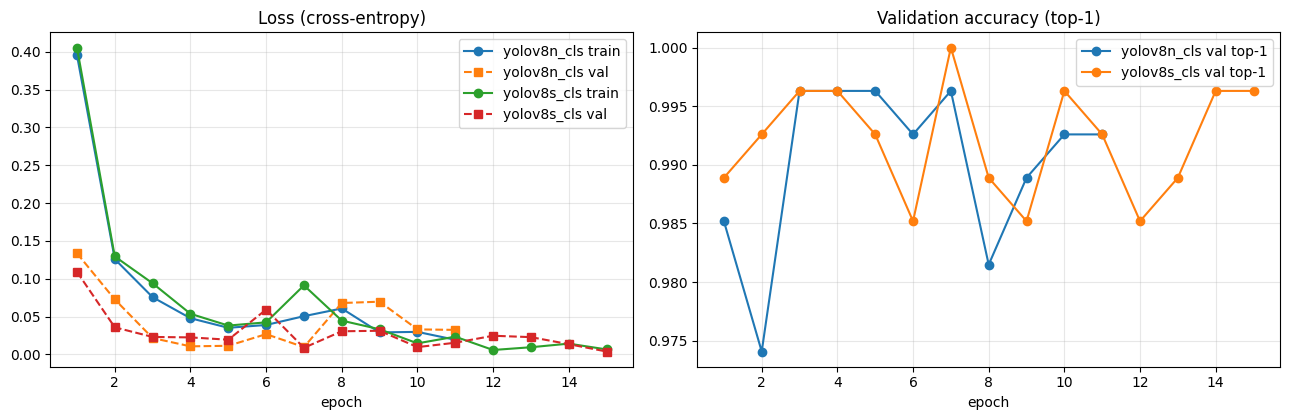

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for name in VARIANTS:
    res = pd.read_csv(RUNS / name / "results.csv"); res.columns = [c.strip() for c in res.columns]
    res.to_csv(OUT / f"{name}_results.csv", index=False)
    axes[0].plot(res["epoch"], res["train/loss"], "o-", label=f"{name} train")
    axes[0].plot(res["epoch"], res["val/loss"], "s--", label=f"{name} val")
    axes[1].plot(res["epoch"], res["metrics/accuracy_top1"], "o-", label=f"{name} val top-1")
    print(f"--- {name}"); print(res[["epoch", "train/loss", "val/loss", "metrics/accuracy_top1"]].round(4).to_string(index=False))
axes[0].set_title("Loss (cross-entropy)"); axes[1].set_title("Validation accuracy (top-1)")
for ax in axes: ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); fig.savefig(OUT / "yolo_curves.png", dpi=120); plt.show()

## 3. Evaluation on the test split (used once)

Predictions come from `best.pt`. The probability of the class **bad** is passed to the same `compute_metrics` / `breakdown` functions as in Task 2, with threshold 0.5. With 2 softmax classes this equals the argmax.

In [5]:
test_records = qc.load_split()["test"]
y_test = np.array([qc.CLASS_TO_LABEL[r["quality_label"]] for r in test_records])
test_paths = [str(DATA / "test" / r["quality_label"] / Path(r["image_path"]).name) for r in test_records]

def predict_bad(model, paths, batch=32):
    bad_idx = [k for k, v in model.names.items() if v == "bad"][0]
    probs = []
    for i in range(0, len(paths), batch):
        for r in model.predict(paths[i:i + batch], imgsz=HP["imgsz"], device="cpu", verbose=False):
            probs.append(float(r.probs.data[bad_idx]))
    return np.array(probs)

report, rows = {}, []
for name in VARIANTS:
    best_path = RUNS / name / "weights" / "best.pt"
    model = YOLO(best_path)
    p_bad = predict_bad(model, test_paths)
    pd.DataFrame({"image_id": [r["image_id"] for r in test_records], "prob_bad": p_bad}) \
      .to_csv(OUT / f"{name}_test_predictions.csv", index=False)

    m = qc.compute_metrics(y_test, p_bad)
    parts = qc.breakdown(test_records, p_bad)
    net = model.model.float().eval()
    lat_mean, lat_std = qc.cpu_latency_ms(net)              # same protocol as Task 1/2
    size_fp32 = qc.model_size_mb(net)
    total = sum(p.numel() for p in net.parameters())
    checks = qc.acceptance_check(m, parts, lat_mean, size_fp32)
    info = train_info[name]
    report[name] = {"metrics": m, "breakdown": parts, "cpu_latency_ms": [round(lat_mean, 1), round(lat_std, 1)],
                    "size_mb_fp32": round(size_fp32, 1), "best_pt_file_mb": round(best_path.stat().st_size / 1024**2, 1),
                    "params_total": total, "train_time_s": round(info["train_time_s"], 1),
                    "epochs_run": info["epochs_run"], "best_epoch": info["best_epoch"], "acceptance": checks}
    rows.append({"model": name, "accuracy": m["accuracy"], "precision_bad": m["precision_bad"],
                 "recall_bad": m["recall_bad"], "f1_bad": m["f1_bad"], "f1_macro": m["f1_macro"],
                 "cpu_latency_ms": round(lat_mean, 1), "size_mb_fp32": round(size_fp32, 1),
                 "params_M": round(total / 1e6, 2), "train_time_s": round(info["train_time_s"]),
                 "best_epoch": info["best_epoch"]})
summary = pd.DataFrame(rows).set_index("model")
summary.round(4)

,accuracy,precision_bad,recall_bad,f1_bad,f1_macro,cpu_latency_ms,size_mb_fp32,params_M,train_time_s,best_epoch
model,,,,,,,,,,
yolov8n_cls,0.9963,1.0,0.9926,0.9963,0.9963,10.1,5.6,1.44,346,3
yolov8s_cls,1.0000,1.0,1.0000,1.0000,1.0000,17.7,19.5,5.08,1034,7


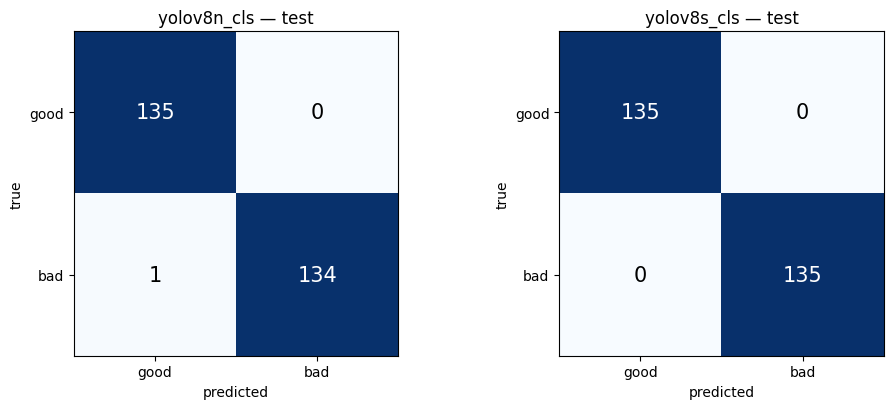

===== yolov8n_cls
recall(bad) per defect:      {'blur': 1.0, 'exposure': 0.9643, 'glare': 1.0, 'occlusion': 1.0, 'skew': 1.0}
accuracy(good) per aug:      {'none': 1.0, 'rotate_270': 1.0, 'rotate_90': 1.0, 'slight_rotation': 1.0, 'upside_down': 1.0}
accuracy per document class: {'inn': 0.9889, 'passport': 1.0, 'snils': 1.0}
   PASS  Q1 accuracy >= 0.92
   PASS  Q2 F1(bad) >= 0.92
   PASS  Q3 recall(bad) >= 0.93
   PASS  Q4 precision(bad) >= 0.88
   PASS  Q5 recall per defect >= 0.85
   PASS  C1 CPU latency <= 50 ms
   PASS  C2 size <= 25 MB
===== yolov8s_cls
recall(bad) per defect:      {'blur': 1.0, 'exposure': 1.0, 'glare': 1.0, 'occlusion': 1.0, 'skew': 1.0}
accuracy(good) per aug:      {'none': 1.0, 'rotate_270': 1.0, 'rotate_90': 1.0, 'slight_rotation': 1.0, 'upside_down': 1.0}
accuracy per document class: {'inn': 1.0, 'passport': 1.0, 'snils': 1.0}
   PASS  Q1 accuracy >= 0.92
   PASS  Q2 F1(bad) >= 0.92
   PASS  Q3 recall(bad) >= 0.93
   PASS  Q4 precision(bad) >= 0.88
   PASS  

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (name, rep) in zip(axes, report.items()):
    cm = np.array(rep["metrics"]["confusion_matrix"])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=15,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["good", "bad"]); ax.set_yticks([0, 1], ["good", "bad"])
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{name} — test")
    qc.plot_confusion(cm, f"{name} — test", OUT / f"{name}_confusion_matrix.png"); plt.close()
plt.tight_layout(); plt.show()

for name, rep in report.items():
    print(f"===== {name}")
    print("recall(bad) per defect:     ", rep["breakdown"]["recall_bad_per_defect"])
    print("accuracy(good) per aug:     ", rep["breakdown"]["accuracy_good_per_augmentation"])
    print("accuracy per document class:", rep["breakdown"]["accuracy_per_document_class"])
    for crit, ok in rep["acceptance"].items():
        print(f"   {'PASS' if ok else 'FAIL'}  {crit}")

## 4. Comparison with the Task 2 baseline (same test split)

The Task 2 numbers are read from `../task2/outputs/test_metrics.json`. They come from the same 270 test images and were measured with the same metric and latency code.

In [7]:
t2 = json.loads((Path.cwd().parent / "task2" / "outputs" / "test_metrics.json").read_text())["results"]
cmp_rows = []
for name, rep in {**{k: v for k, v in t2.items()}, **report}.items():
    m = rep["metrics"]
    cmp_rows.append({"model": name, "task": "task2 (frozen)" if name in t2 else "task3 (full fine-tune)",
                     "accuracy": m["accuracy"], "precision_bad": m["precision_bad"], "recall_bad": m["recall_bad"],
                     "f1_bad": m["f1_bad"], "FN (missed bad)": m["confusion_matrix"][1][0],
                     "FP (false alarm)": m["confusion_matrix"][0][1],
                     "cpu_latency_ms": rep["cpu_latency_ms"][0],
                     "size_mb_fp32": rep.get("size_mb_fp32", rep.get("size_mb")),
                     "params_M": round(rep["params_total"] / 1e6, 2), "train_time_s": round(rep["train_time_s"])})
comparison = pd.DataFrame(cmp_rows).set_index("model")
comparison.to_csv(OUT / "comparison_with_task2.csv")
comparison.round(4)

,task,accuracy,precision_bad,recall_bad,f1_bad,FN (missed bad),FP (false alarm),cpu_latency_ms,size_mb_fp32,params_M,train_time_s
model,,,,,,,,,,,
mobilenet_v3_small,task2 (frozen),0.9778,0.9924,0.9630,0.9774,5,1,8.9,3.9,1.00,203
mobilenet_v2,task2 (frozen),0.9852,0.9852,0.9852,0.9852,2,2,17.6,9.3,2.39,983
yolov8n_cls,task3 (full fine-tune),0.9963,1.0000,0.9926,0.9963,1,0,10.1,5.6,1.44,346
yolov8s_cls,task3 (full fine-tune),1.0000,1.0000,1.0000,1.0000,0,0,17.7,19.5,5.08,1034


## 5. Save results and the experiment log

In [8]:
(OUT / "test_metrics.json").write_text(json.dumps({"hyperparameters": HP, "results": report}, indent=2, default=str), encoding="utf-8")
summary.to_csv(OUT / "summary.csv")
for name in VARIANTS:                      # keep the Ultralytics plots next to our outputs
    for f in ("confusion_matrix.png", "results.png"):
        src = RUNS / name / f
        if src.exists():
            shutil.copy2(src, OUT / f"{name}_ultralytics_{f}")

log_path = Path.cwd().parent / "experiment_log.csv"
log = pd.DataFrame([{
    "date": time.strftime("%Y-%m-%d %H:%M"), "task": "task3", "model": name, "regime": "full fine-tuning",
    "seed": HP["seed"], "image_size": HP["imgsz"], "batch_size": HP["batch"], "optimizer": HP["optimizer"],
    "lr": HP["lr0"], "epochs_run": rep["epochs_run"], "best_epoch": rep["best_epoch"], "train_time_s": rep["train_time_s"],
    "test_accuracy": round(rep["metrics"]["accuracy"], 4), "test_precision_bad": round(rep["metrics"]["precision_bad"], 4),
    "test_recall_bad": round(rep["metrics"]["recall_bad"], 4), "test_f1_bad": round(rep["metrics"]["f1_bad"], 4),
    "cpu_latency_ms": rep["cpu_latency_ms"][0], "size_mb": rep["size_mb_fp32"],
} for name, rep in report.items()])
old = pd.read_csv(log_path)
log = pd.concat([old[old["task"] != "task3"], log], ignore_index=True)
log.to_csv(log_path, index=False)
log

,date,task,model,regime,seed,image_size,batch_size,optimizer,lr,epochs_run,best_epoch,train_time_s,test_accuracy,test_precision_bad,test_recall_bad,test_f1_bad,cpu_latency_ms,size_mb
0,2026-11-02 15:24,task2,mobilenet_v3_small,frozen base,24500003,224,32,Adam,0.001,30,26,202.9,0.9778,0.9924,0.9630,0.9774,8.9,3.9
1,2026-11-02 15:24,task2,mobilenet_v2,frozen base,24500003,224,32,Adam,0.001,28,23,983.0,0.9852,0.9852,0.9852,0.9852,17.6,9.3
2,2026-11-08 20:40,task3,yolov8n_cls,full fine-tuning,24500003,224,32,AdamW,0.001,11,3,346.4,0.9963,1.0000,0.9926,0.9963,10.1,5.6
3,2026-11-08 20:40,task3,yolov8s_cls,full fine-tuning,24500003,224,32,AdamW,0.001,15,7,1033.5,1.0000,1.0000,1.0000,1.0000,17.7,19.5


## 6. Interpretation

**Test results (270 images, the same split as Task 2):**

| Model | Regime | Accuracy | Precision (bad) | Recall (bad) | F1 (bad) | FN / FP | CPU latency | Size fp32 | Train time |
|---|---|---|---|---|---|---|---|---|---|
| MobileNetV3-Small (Task 2) | frozen | 0.978 | 0.992 | 0.963 | 0.977 | 5 / 1 | 8.9 ms | 3.9 MB | 3.4 min |
| MobileNetV2 (Task 2) | frozen | 0.985 | 0.985 | 0.985 | 0.985 | 2 / 2 | 17.6 ms | 9.3 MB | 16.4 min |
| **YOLOv8n-cls** | full fine-tune | **0.996** | 1.000 | 0.993 | 0.996 | **1 / 0** | **10.1 ms** | 5.6 MB | 5.8 min |
| YOLOv8s-cls | full fine-tune | **1.000** | 1.000 | 1.000 | 1.000 | 0 / 0 | 17.7 ms | 19.5 MB | 17.2 min |

**Training output.**
- **Convergence is fast.** Both models reach ≥ 0.985 validation top-1 after the first epoch: the pretrained YOLOv8 backbone adapts to the task almost immediately.
- **Overfitting after the best epoch.** The best validation epoch is 3 for nano and 7 for small. After that, training loss keeps falling (nano: 0.048 → 0.019) while validation loss becomes noisy and partly rises (nano: 0.010 → 0.068 at epoch 8–9). This is the start of overfitting when all 1.4–5 M parameters are trained on 1260 images.
- **Why it does not hurt the result.** Early stopping (patience 8) ends training, and `best.pt` keeps the weights of the best validation epoch, so the evaluated models are not overfitted.
- **Top-5 is meaningless here.** With 2 classes it is always 1.0.

**Errors.**
- YOLOv8n makes **one** mistake: an INN image with the *exposure* defect predicted as good, with P(bad) = 0.39, close to the threshold. Overexposure on the white INN form is weak; the Homework 3 audit already flagged it as possible label noise.
- YOLOv8s classifies all 270 test images correctly.
- No rotated GOOD image is misclassified, so the rotation augmentation removed the "rotated = good" shortcut for YOLO as well.

**Why YOLO is more accurate than the Task 2 MobileNets.**
1. **Training regime, the main factor.** YOLO trains *all* layers (full fine-tuning). In Task 2 only the 74–164 k head parameters were trained on top of fixed ImageNet features. Fine-tuning lets the convolution filters adapt to document-specific defects: lost text strokes (blur), dark blocks (occlusion), global brightness shift (exposure). The MobileNetV3-Small errors were exactly occlusion and exposure. The fine-tuning bonus in Task 4 tests how much of the gap is the regime and how much is the architecture.
2. **Architecture.** YOLOv8-cls uses dense 3×3 convolutions in C2f/CSP blocks. They hold more capacity per layer than MobileNet's depthwise-separable blocks and still run fast on CPU.
3. **Same input.** All models use 224×224 inputs from the same split, so input size does not explain the difference.

**Speed and size.**
- **YOLOv8n vs MobileNetV3-Small.** YOLOv8n is only 1.2 ms slower (10.1 vs 8.9 ms) but makes 6× fewer errors (1 vs 6). Its FLOPs are higher, but plain dense convolutions use the CPU's vector units better than depthwise convolutions with squeeze-and-excitation, so the latencies end up close.
- **YOLOv8s vs MobileNetV2.** YOLOv8s runs at the same speed as MobileNetV2 (17.7 vs 17.6 ms) but is 2× larger (19.5 MB), still under the 25 MB budget.

**How sure is the difference between nano and small?** The test set has 270 images, so 1.000 vs 0.996 is a difference of **one image**. By the "rule of three", 0 errors in 270 means the true error rate can still be up to ~1.1 % (95 % confidence). The two YOLO variants are therefore statistically indistinguishable in quality.

**Conclusion.**
- Both YOLO variants pass every acceptance criterion from the Task 1 memo.
- **YOLOv8n-cls** gives practically the same quality as YOLOv8s at **1.75× lower latency and 3.5× smaller size**. It is the strongest candidate for the first gate so far.
- The final decision is made in Task 4, after EfficientNet-B0 and the fine-tuning experiment.
